# Phase 3, experiment 3: why are steps 24, 29, 31 and 32 weak?

**Why this analysis:** In every model tried so far, four validation steps (24, 29, 31, 32) score an
AUC of about 0.73 to 0.79 while the other ten validation steps score about 0.985. These four steps
hold about half of the illicit rows in validation, so they decide the overall validation AUC.

**Questions:**

1. In the weak steps, is the model missing illicit transactions (giving them low scores), or flagging
   licit ones (giving them high scores)?
2. Do the illicit transactions it misses look different, in their features, from the illicit
   transactions it was trained on?
3. Do they look different in the graph (who they are connected to)?
4. Did this kind of illicit transaction appear in the training period at all?

This notebook only analyses the baseline model's validation predictions. No new model is selected and
nothing is submitted. The validation labels are used here only to understand the errors.

## 1. Load, split and train the baseline

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

SEED = 42
DATA_DIR = "../data"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
edges = pd.read_csv(f"{DATA_DIR}/txs_edgelist.csv")

raw_cols = [c for c in train.columns if c.startswith("feat_")]

# Labeled rows only (1 = illicit, 0 = licit)
labeled = train[train["label"].notna()].copy()
labeled["label"] = labeled["label"].astype(int)

# Same split: train on steps 1-21, validate on steps 22-35
TRAIN_LAST_STEP = 21
tr = labeled[labeled["time_step"] <= TRAIN_LAST_STEP]
va = labeled[labeled["time_step"] > TRAIN_LAST_STEP].copy()

# Baseline model: LightGBM defaults on the raw features
model = lgb.LGBMClassifier(random_state=SEED, verbose=-1)
model.fit(tr[raw_cols], tr["label"])

va["pred"] = model.predict_proba(va[raw_cols])[:, 1]   # predicted probability of illicit
print("Validation AUC:", round(roc_auc_score(va["label"], va["pred"]), 4))

# Mark each validation row as belonging to a weak step or not
WEAK_STEPS = [24, 29, 31, 32]
va["step_group"] = np.where(va["time_step"].isin(WEAK_STEPS), "weak", "other")

Validation AUC: 0.9148


## 2. Is the model missing illicit rows or flagging licit rows?

AUC is low when illicit rows get lower scores than licit rows. That can happen in two ways: illicit
rows get low scores, or licit rows get high scores. The tables below show the predicted scores for
each class, split into the weak steps and the other steps.

In [3]:
# Summary of the predicted score for each class and step group.
# For illicit rows a good model gives scores near 1; for licit rows, near 0.
score_summary = va.groupby(["label", "step_group"])["pred"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
score_summary.round(3)

count   mean    std  min    10%    25%    50%    75%  \
label step_group                                                          
0     other       6513.0  0.008  0.062  0.0  0.000  0.000  0.000  0.000   
      weak        3419.0  0.012  0.073  0.0  0.000  0.000  0.000  0.001   
1     other        859.0  0.883  0.289  0.0  0.323  0.995  0.999  1.000   
      weak         914.0  0.480  0.483  0.0  0.000  0.000  0.261  0.998   

                    90%    max  
label step_group                
0     other       0.002  0.994  
      weak        0.008  0.998  
1     other       1.000  1.000  
      weak        0.999  1.000

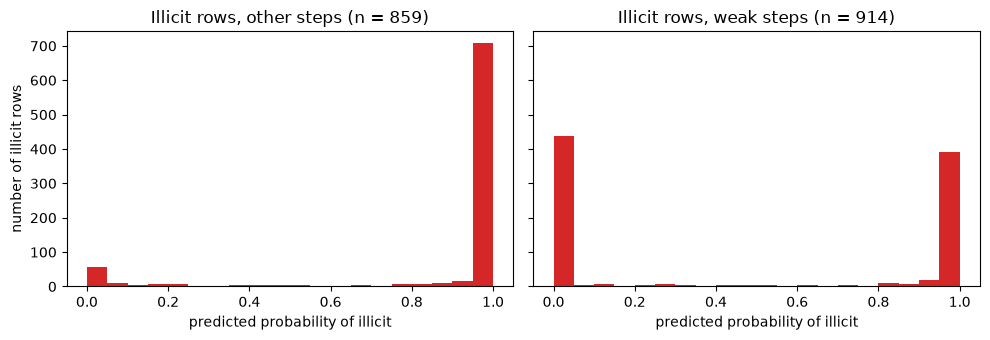

In [4]:
# Histogram of the scores given to illicit rows, weak steps against the other steps
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, group in zip(axes, ["other", "weak"]):
    scores = va.loc[(va["label"] == 1) & (va["step_group"] == group), "pred"]
    ax.hist(scores, bins=20, range=(0, 1), color="tab:red")
    ax.set_title(f"Illicit rows, {group} steps (n = {len(scores)})")
    ax.set_xlabel("predicted probability of illicit")
axes[0].set_ylabel("number of illicit rows")
plt.tight_layout()
plt.show()

To study the errors, the illicit validation rows are put into two groups:

- **missed**: illicit rows the model scored below 0.05 (it was confident they were licit)
- **caught**: illicit rows the model scored 0.5 or above

The 0.05 and 0.5 cut-offs are only for this analysis. They are not used for any prediction.

In [5]:
MISSED_BELOW = 0.05
CAUGHT_FROM = 0.5

va_illicit = va[va["label"] == 1]
missed = va_illicit[va_illicit["pred"] < MISSED_BELOW]
caught = va_illicit[va_illicit["pred"] >= CAUGHT_FROM]

print("Illicit validation rows:", len(va_illicit))
print("  missed (score < 0.05):", len(missed), " of which in weak steps:", missed["time_step"].isin(WEAK_STEPS).sum())
print("  caught (score >= 0.5):", len(caught))

# Share of each step's illicit rows that the model missed
per_step = va_illicit.groupby("time_step").agg(
    n_illicit=("pred", "size"),
    n_missed=("pred", lambda s: (s < MISSED_BELOW).sum()),
)
per_step["share_missed"] = per_step["n_missed"] / per_step["n_illicit"]
per_step.round(3)

Illicit validation rows: 1773
  missed (score < 0.05): 494  of which in weak steps: 438
  caught (score >= 0.5): 1200


,n_illicit,n_missed,share_missed
time_step,,,
22,158,3,0.019
23,53,13,0.245
24,137,86,0.628
25,118,0,0.000
26,96,20,0.208
27,24,1,0.042
28,85,0,0.000
29,329,195,0.593
30,83,8,0.096


## 3. Do the missed illicit rows look different in their features?

For each feature, compare the average value in four groups: missed illicit, caught illicit, and the
illicit and licit rows of the training period.

To put all features on one scale, each difference is divided by the feature's standard deviation in
the training period. A value of 1.0 means "one standard deviation higher than the comparison group".
Values near 0 mean the two groups look alike on that feature.

In [ ]:
tr_illicit = tr[tr["label"] == 1]
tr_licit = tr[tr["label"] == 0]
feature_std = tr[raw_cols].std()   # spread of each feature in the training period

diff = pd.DataFrame({
    # how often the model splits on the feature (higher = more relied on)
    "importance": pd.Series(model.feature_importances_, index=raw_cols),
    # missed illicit compared with the illicit rows the model learned from
    "missed_vs_train_illicit": (missed[raw_cols].mean() - tr_illicit[raw_cols].mean()) / feature_std,
    # missed illicit compared with the licit rows the model learned from
    "missed_vs_train_licit": (missed[raw_cols].mean() - tr_licit[raw_cols].mean()) / feature_std,
    # caught illicit compared with the illicit rows the model learned from
    "caught_vs_train_illicit": (caught[raw_cols].mean() - tr_illicit[raw_cols].mean()) / feature_std,
})

# Average size of the differences over all 165 features 
print("Average absolute difference over all features:")
print(diff.drop(columns="importance").abs().mean().round(3))

# The 15 features the model relies on most
diff.sort_values("importance", ascending=False).head(15).round(2)

Average absolute difference over all features:
missed_vs_train_illicit    0.347
missed_vs_train_licit      0.351
caught_vs_train_illicit    0.130
dtype: float64


,importance,missed_vs_train_illicit,missed_vs_train_licit,caught_vs_train_illicit
feat_2,298,0.19,0.08,0.29
feat_53,120,0.84,-0.20,-0.02
feat_58,81,-0.00,-0.12,-0.00
feat_138,69,0.42,0.17,-0.02
feat_52,65,0.94,0.30,-0.01
feat_16,61,-0.03,-0.12,-0.01
feat_8,60,0.13,-0.05,-0.00
feat_142,55,-0.74,0.06,0.96
feat_88,55,0.87,0.68,-0.02
feat_5,50,0.01,-0.05,-0.00


## 4. Do the missed illicit rows look different in the graph?

For each group of transactions, look at every edge that touches a transaction in the group and ask what
the transaction at the other end is: labeled illicit, labeled licit, unlabeled, or outside train/test.

In [7]:
# Lookup tables for the neighbour's label
illicit_ids = set(labeled.loc[labeled["label"] == 1, "txId"])
licit_ids = set(labeled.loc[labeled["label"] == 0, "txId"])
unlabeled_ids = set(train.loc[train["label"].isna(), "txId"])

def neighbour_summary(group_ids):
    # Describe the neighbours of the transactions in group_ids.
    group_ids = set(group_ids)

    # Edges where the group transaction is the source: the neighbour is txId2
    out_nb = edges.loc[edges["txId1"].isin(group_ids), "txId2"]
    # Edges where the group transaction is the destination: the neighbour is txId1
    in_nb = edges.loc[edges["txId2"].isin(group_ids), "txId1"]
    neighbours = pd.concat([out_nb, in_nb])

    return {
        "n_transactions": len(group_ids),
        "n_edges": len(neighbours),
        "share_nb_illicit": neighbours.isin(illicit_ids).mean(),
        "share_nb_licit": neighbours.isin(licit_ids).mean(),
        "share_nb_unlabeled": neighbours.isin(unlabeled_ids).mean(),
        "share_nb_same_group": neighbours.isin(group_ids).mean(),
    }

groups = {
    "missed illicit (validation)": missed["txId"],
    "caught illicit (validation)": caught["txId"],
    "illicit (training period)": tr_illicit["txId"],
    "licit (validation)": va.loc[va["label"] == 0, "txId"],
}
neighbour_table = pd.DataFrame({name: neighbour_summary(ids) for name, ids in groups.items()}).T
neighbour_table.round(3)

,n_transactions,n_edges,share_nb_illicit,share_nb_licit,share_nb_unlabeled,share_nb_same_group
missed illicit (validation),494.0,1106.0,0.809,0.080,0.111,0.783
caught illicit (validation),1200.0,2978.0,0.105,0.158,0.737,0.087
illicit (training period),1871.0,3033.0,0.146,0.224,0.630,0.146
licit (validation),9932.0,28561.0,0.021,0.566,0.413,0.566


## 5. Did this pattern exist in the training period?

Section 4 looks at illicit transactions that are connected to other illicit transactions. This section
checks how common that is in each of the 35 training time steps, to see whether the model had examples
of it to learn from.

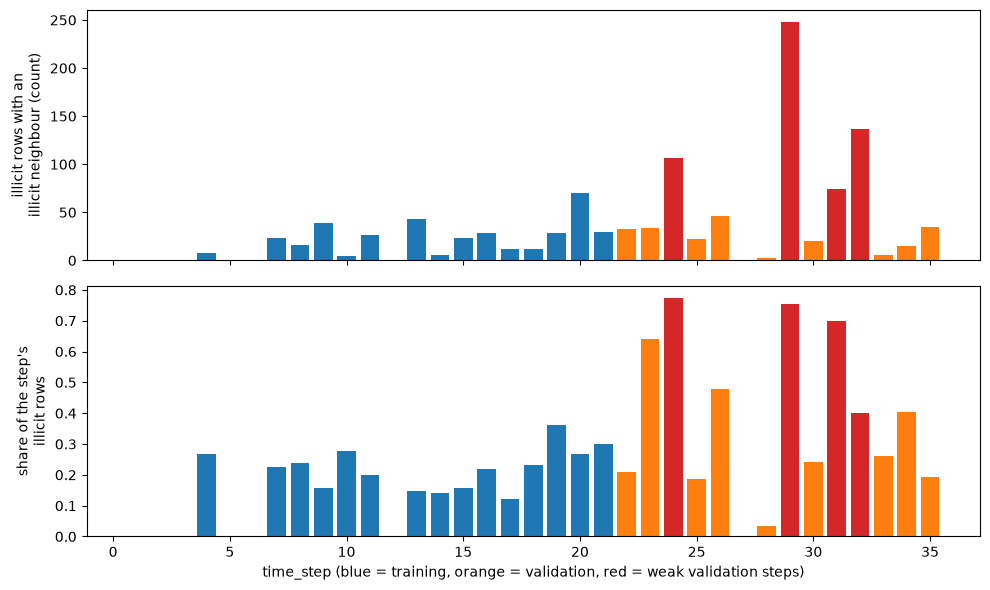

,n_illicit,n_with_illicit_nb,share_with_illicit_nb
time_step,,,
1,17,0,0.000
2,18,0,0.000
3,11,0,0.000
4,30,8,0.267
5,8,0,0.000
6,5,0,0.000
7,102,23,0.225
8,67,16,0.239
9,248,39,0.157


In [8]:
# For every labeled illicit transaction, count how many of its neighbours are also labeled illicit.
# Each edge between two illicit transactions adds 1 to both of its endpoints.
both_illicit = edges[edges["txId1"].isin(illicit_ids) & edges["txId2"].isin(illicit_ids)]
n_illicit_nb = pd.concat([both_illicit["txId1"], both_illicit["txId2"]]).value_counts()

all_illicit = labeled[labeled["label"] == 1].copy()
all_illicit["n_illicit_nb"] = all_illicit["txId"].map(n_illicit_nb).fillna(0)
all_illicit["has_illicit_nb"] = all_illicit["n_illicit_nb"] > 0

by_step = all_illicit.groupby("time_step").agg(
    n_illicit=("txId", "size"),
    n_with_illicit_nb=("has_illicit_nb", "sum"),
)
by_step["share_with_illicit_nb"] = by_step["n_with_illicit_nb"] / by_step["n_illicit"]

# Bar chart over all 35 steps. Validation steps are orange, and the weak ones are red.
colors = []
for step in by_step.index:
    if step in WEAK_STEPS:
        colors.append("tab:red")
    elif step > TRAIN_LAST_STEP:
        colors.append("tab:orange")
    else:
        colors.append("tab:blue")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].bar(by_step.index, by_step["n_with_illicit_nb"], color=colors)
axes[0].set_ylabel("illicit rows with an\nillicit neighbour (count)")
axes[1].bar(by_step.index, by_step["share_with_illicit_nb"], color=colors)
axes[1].set_ylabel("share of the step's\nillicit rows")
axes[1].set_xlabel("time_step (blue = training, orange = validation, red = weak validation steps)")
plt.tight_layout()
plt.show()

by_step.round(3)

## Findings

- **Missing illicit rows or flagging licit rows?** The model is missing illicit rows. Licit rows get
  scores near 0 in both groups of steps (90% of licit rows score below 0.01). Illicit rows in the other
  steps get a median score of 0.999, but in the weak steps the median is 0.26 and a quarter of them
  score essentially 0. In total 494 illicit validation rows score below 0.05, and 438 of those are in
  the four weak steps. The share of illicit rows missed is 63% in step 24, 59% in step 29, 49% in
  step 31 and 31% in step 32, against 0% to 25% in the other steps.
- **Do the missed illicit rows differ in their features?** Yes. The caught illicit rows look like the
  illicit rows of the training period (average difference of 0.13 standard deviations per feature).
  The missed ones do not (0.35), and they are about as far from training illicit rows as they are from
  training licit rows (0.35). Several of the features the model relies on most are shifted by 0.7 to 1.0
  standard deviations for the missed rows (`feat_53`, `feat_52`, `feat_55`, `feat_88`, `feat_89`, `feat_142`).
- **Do they differ in the graph?** Yes, strongly. 81% of the neighbours of missed illicit rows are
  labeled illicit, against 11% for caught illicit rows and 15% for illicit rows in the training
  period. 78% of their neighbours are other missed rows, so the missed transactions form connected
  groups of illicit transactions. Caught illicit rows are mostly connected to unlabeled transactions (74%).
- **Was the pattern present in the training period?** Only weakly. In training steps 1 to 21, between
  0% and 36% of a step's illicit rows have a labeled illicit neighbour (usually 15% to 30%). In the
  weak validation steps it is 77% (step 24), 75% (step 29), 70% (step 31) and 40% (step 32). Step 23
  (64%) and step 26 (48%) are also high, and they are the two next-weakest steps. So the model had few
  examples of this kind of illicit transaction to learn from.

